# Chapter 04 — The Unreasonable Effectiveness of Linear Regression & FWL
> *Reference: Paraphrased from Matheus Facure's Causal Inference in Python (Chapter 4).*

Linear regression is one of the most powerful tools for causal inference when controlling for observed confounders.
This notebook demonstrates:
1. **Omitted Variable Bias** in estimating the returns to education (`wage.csv`).
2. **Multivariate Causal Regression** with heteroskedasticity-robust standard errors (`LinearRegression` / `OLS`).
3. **Distribution-First Treatment Effects**: Each coefficient as a first-class `StudentsT` sampling distribution.
4. **Frisch-Waugh-Lovell (FWL) Theorem**: Exact partialling-out decomposition via `.fwl_decompose()` and `.plot_fwl()`.
5. **Confounder Residualization on Distributions**: `Ratio.residualize()` to create debiased continuous distributions.

In [1]:
import set_paths
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from make_data import load_wage
from probability.distributions import Ratio, StudentsT
from probability.models import LinearRegression, OLS

## 4.1 Omitted Variable Bias: Returns to Education
Does education cause higher wages, or do high-ability individuals obtain more education AND earn higher wages?
We inspect the Young Men National Longitudinal Survey (`wage.csv`).

In [2]:
wage_df = load_wage().dropna(subset=['wage', 'educ', 'IQ', 'exper', 'tenure', 'age'])
print(f"Sample size: {len(wage_df)} workers")
wage_df[['wage', 'educ', 'IQ', 'exper', 'tenure', 'age']].head()

Sample size: 935 workers


,wage,educ,IQ,exper,tenure,age
0,769,12,93,11,2,31
1,808,18,119,11,16,37
2,825,14,108,11,9,33
3,650,12,96,13,7,32
4,562,11,74,14,5,34


### Naive Bivariate Model
Regressing hourly wage solely on education ignores ability (`IQ`) and experience, yielding a heavily biased slope.

In [3]:
naive_model = LinearRegression.fit(
    X=wage_df[['educ']],
    y=wage_df['wage'],
    cov_type='HC3'
)
print('--- Naive Bivariate Model (Omitted Variable Bias) ---')
naive_model.summary().round(3)

--- Naive Bivariate Model (Omitted Variable Bias) ---


,coef,std_err,t_stat,p_value,95% CI lower,95% CI upper,df
feature,,,,,,,
intercept,146.952,80.486,1.826,0.068,-11.002,304.907,933.0
educ,60.214,6.175,9.752,0.000,48.096,72.332,933.0


## 4.2 Multivariate Causal Regression with Robust Standard Errors
By controlling for `IQ`, `exper`, `tenure`, `age`, and `married`, we partial out ability and maturity bias.
We use `cov_type='HC3'` for heteroskedasticity-consistent standard errors.

In [4]:
controls = ['educ', 'IQ', 'exper', 'tenure', 'age', 'married']
causal_model = LinearRegression.fit(
    X=wage_df[controls],
    y=wage_df['wage'],
    cov_type='HC3'
)
print('--- Multivariate Controlled Causal Model (HC3 SE) ---')
causal_model.summary().round(3)

--- Multivariate Controlled Causal Model (HC3 SE) ---


,coef,std_err,t_stat,p_value,95% CI lower,95% CI upper,df
feature,,,,,,,
intercept,-929.079,170.394,-5.453,0.000,-1263.481,-594.678,928.0
educ,53.316,7.263,7.340,0.000,39.061,67.570,928.0
IQ,4.976,0.878,5.669,0.000,3.253,6.699,928.0
exper,9.471,3.880,2.441,0.015,1.856,17.086,928.0
tenure,5.882,2.531,2.324,0.020,0.914,10.850,928.0
age,10.877,4.991,2.179,0.030,1.082,20.673,928.0
married,171.388,35.772,4.791,0.000,101.183,241.592,928.0


## 4.3 Distribution-First Treatment Effect (`StudentsT`)
The `probability` library treats regression coefficients as exact Student's t sampling distributions.
This enables immediate probabilistic queries like $P(\beta_{\text{educ}} > 0)$, exact HDI intervals, and testing.

In [5]:
beta_educ = causal_model.coefficient('educ')
print(f"Education Coefficient: StudentsT(nu={beta_educ.nu:.0f}, mu={beta_educ.mu:.3f}, sigma={beta_educ.sigma:.3f})")
print(f"P(beta_educ > 0):       {float(beta_educ > 0):.4%}")
print(f"P(beta_educ > $30/yr):   {float(beta_educ > 30):.2%}")
print(f"95% HDI Interval:        {beta_educ.interval(0.95)}")

Education Coefficient: StudentsT(nu=928, mu=53.316, sigma=7.263)
P(beta_educ > 0):       100.0000%
P(beta_educ > $30/yr):   99.93%
95% HDI Interval:        (np.float64(39.061134783213845), np.float64(67.57013617763079))


## 4.4 Frisch-Waugh-Lovell (FWL) Theorem
The Frisch-Waugh-Lovell theorem proves that multivariate regression is equivalent to:
1. Partialling out all other covariates from the treatment (`educ` $\to \tilde{D}$).
2. Partialling out all other covariates from the outcome (`wage` $\to \tilde{y}$).
3. Running a simple bivariate regression of $\tilde{y}$ on $\tilde{D}$.

In [6]:
tilde_educ, tilde_wage, fwl_bivariate = causal_model.fwl_decompose('educ')
beta_multi = float(causal_model.params['educ'])
beta_fwl = float(fwl_bivariate.params['educ_residualized'])

print(f"Multivariate Coefficient: {beta_multi:.8f}")
print(f"FWL Bivariate Coefficient:{beta_fwl:.8f}")
print(f"Absolute Difference:       {abs(beta_multi - beta_fwl):.2e} (Mathematically Identical!)")

Multivariate Coefficient: 53.31563548
FWL Bivariate Coefficient:53.31563548
Absolute Difference:       4.33e-13 (Mathematically Identical!)


## 4.5 Residualization on Data Distributions (`Ratio.residualize`)
We can directly call `.residualize()` on any `Ratio` distribution to remove confounder variance while preserving the unit scale.

In [7]:
raw_wage = Ratio(wage_df['wage'])
adj_wage = raw_wage.residualize(wage_df[['IQ', 'exper', 'tenure', 'age', 'married']], keep_mean=True)

print(f"Raw Wage Mean:      ${raw_wage.mean():.2f}, SD: ${raw_wage.std():.2f}")
print(f"Adjusted Wage Mean: ${adj_wage.mean():.2f}, SD: ${adj_wage.std():.2f} (Confounder variance filtered)")

Raw Wage Mean:      $957.95, SD: $404.36
Adjusted Wage Mean: $957.95, SD: $373.86 (Confounder variance filtered)


## 4.6 Visualizations: Coefficient Forest Plot & FWL Partialled Scatter Plot
We inspect the full coefficient forest plot and the partialled-out causal relationship.

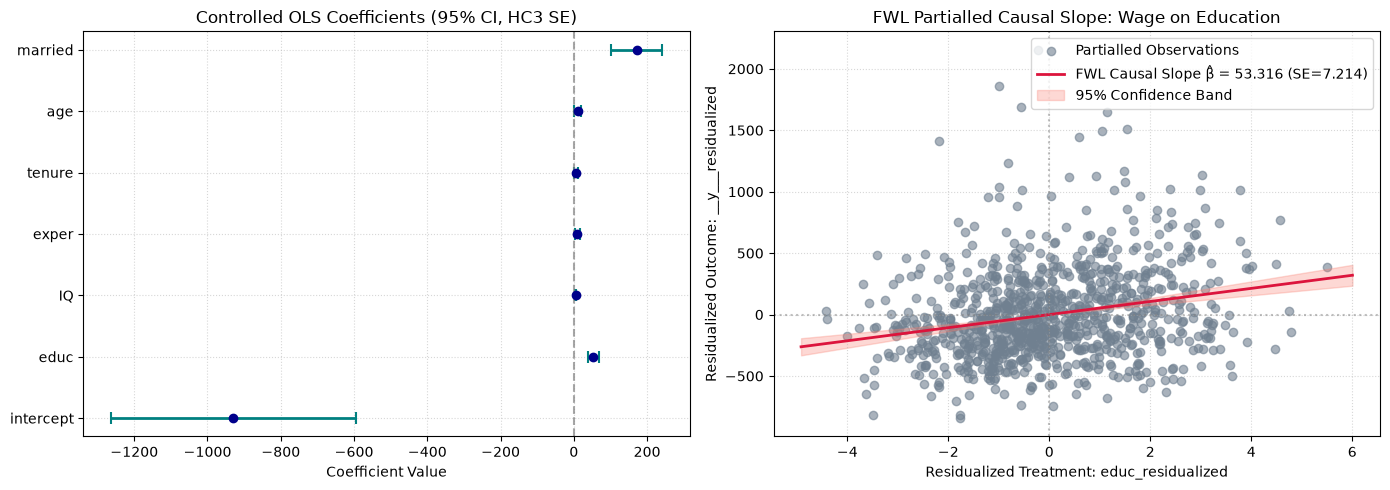

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

causal_model.plot_coefficients(
    hdi=0.95,
    ax=axes[0],
    title="Controlled OLS Coefficients (95% CI, HC3 SE)"
)

causal_model.plot_fwl(
    treatment_var='educ',
    hdi=0.95,
    ax=axes[1],
    title="FWL Partialled Causal Slope: Wage on Education"
)

plt.tight_layout()